In [1]:
# Cell 1: Load the clean dataset and summarize every variable

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

# Load the dataset built in the first notebook
clean = pd.read_csv('clean_utility_data.csv')

# Store the Y and X column names so we only type them once
y_col = 'saidi_wo_major_event_days_minutes'
x_cols = ['underground_share', 'maintenance_per_customer', 'smart_meter_share', 'customers_per_circuit']

# Dataset size
print(f"Rows: {len(clean):,}")
print(f"Utilities: {clean['utility_id_eia'].nunique()}")
print(f"States: {clean['state'].nunique()}")
print(f"Years: {sorted(clean['year'].unique().tolist())}\n")

# Summary statistics for Y and every X
print(clean[[y_col] + x_cols].describe().round(2).T)

Rows: 577
Utilities: 89
States: 46
Years: [2021, 2022, 2023, 2024, 2025]

                                   count    mean     std     min     25%  \
saidi_wo_major_event_days_minutes  577.0  139.74  109.91    2.17   78.80   
underground_share                  577.0    0.38    0.16    0.03    0.27   
maintenance_per_customer           577.0   82.05   58.33    1.72   45.61   
smart_meter_share                  577.0    0.70    0.43    0.00    0.16   
customers_per_circuit              577.0  893.10  439.94  118.82  649.50   

                                      50%      75%      max  
saidi_wo_major_event_days_minutes  108.39   160.12   928.50  
underground_share                    0.39     0.46     0.90  
maintenance_per_customer            67.58   104.01   430.98  
smart_meter_share                    0.99     1.00     1.00  
customers_per_circuit              834.01  1077.01  3692.93  


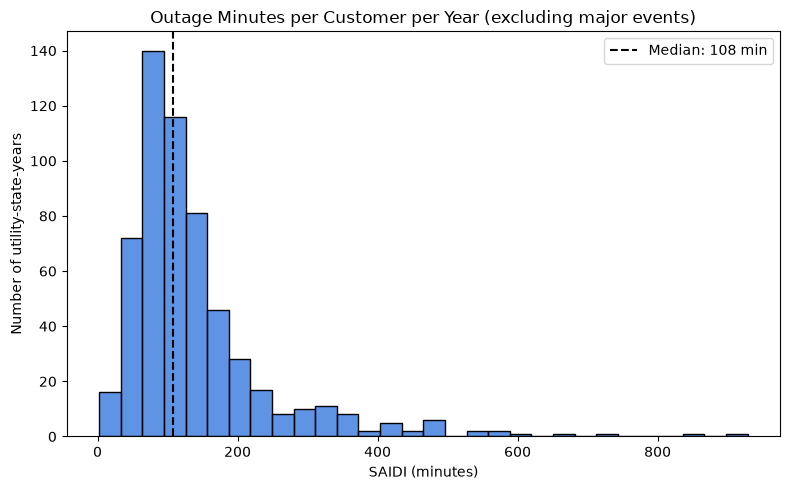

Skew: 2.82


In [2]:
# Cell 2: Distribution of outage minutes

plt.figure(figsize=(8, 5))

# Histogram of SAIDI: 30 bars, each counting rows in that minute range
sns.histplot(clean[y_col], bins=30, color='#2a6fdb')

# Dashed line at the median
plt.axvline(clean[y_col].median(), color='black', linestyle='--', linewidth=1.5,
            label=f"Median: {clean[y_col].median():.0f} min")

plt.title('Outage Minutes per Customer per Year (excluding major events)')
plt.xlabel('SAIDI (minutes)')
plt.ylabel('Number of utility-state-years')
plt.legend()
plt.tight_layout()
plt.show()

# Skew: 0 = symmetric, above 1 = long tail to the right
print(f"Skew: {clean[y_col].skew():.2f}")

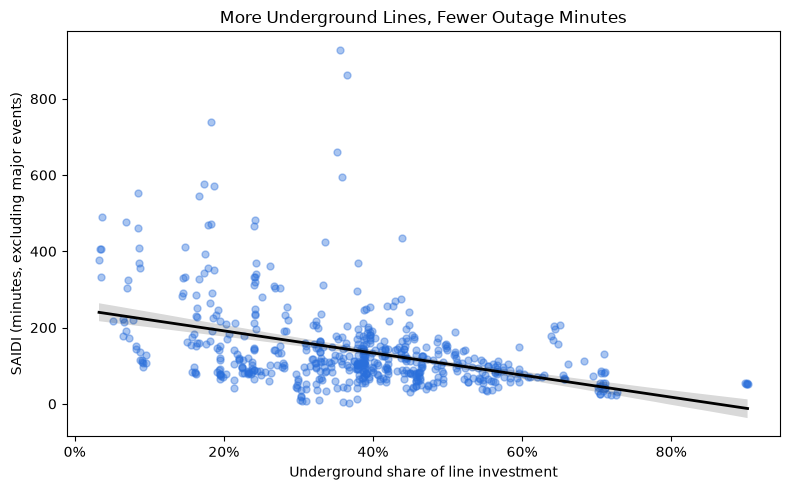

In [3]:
# Cell 3: Scatter plot of outages vs. underground share, with a fitted line

plt.figure(figsize=(8, 5))

# Each dot is one utility-state-year; the line is the best-fit straight line
sns.regplot(data=clean, x='underground_share', y=y_col,
            scatter_kws={'alpha': 0.4, 's': 25, 'color': '#2a6fdb'},
            line_kws={'color': 'black', 'linewidth': 2})

plt.title('More Underground Lines, Fewer Outage Minutes')
plt.xlabel('Underground share of line investment')
plt.ylabel('SAIDI (minutes, excluding major events)')

# Show the x-axis as percentages (0.4 becomes 40%)
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))

plt.tight_layout()
plt.show()

                                   saidi_wo_major_event_days_minutes  \
saidi_wo_major_event_days_minutes                               1.00   
underground_share                                              -0.42   
maintenance_per_customer                                        0.44   
smart_meter_share                                              -0.02   
customers_per_circuit                                          -0.02   

                                   underground_share  \
saidi_wo_major_event_days_minutes              -0.42   
underground_share                               1.00   
maintenance_per_customer                       -0.32   
smart_meter_share                               0.07   
customers_per_circuit                           0.19   

                                   maintenance_per_customer  \
saidi_wo_major_event_days_minutes                      0.44   
underground_share                                     -0.32   
maintenance_per_customer                 

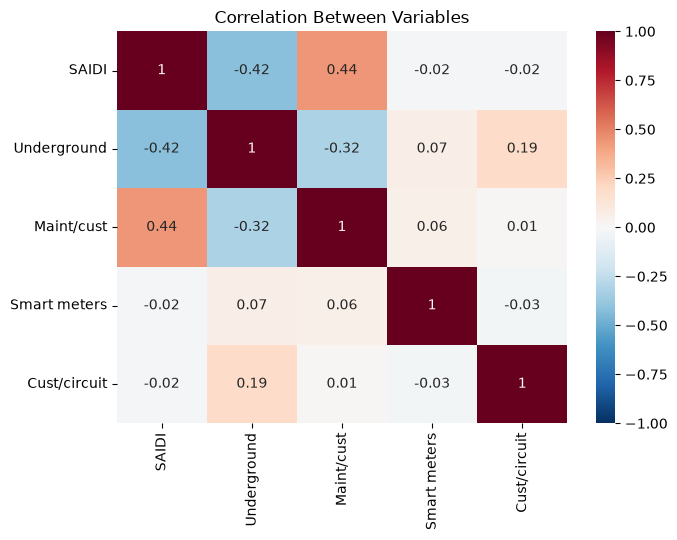

In [4]:
# Cell 4: How strongly each variable moves with every other variable

corr = clean[[y_col] + x_cols].corr().round(2)
print(corr)

# Heatmap: red = move together, blue = move opposite, white = unrelated
labels = ['SAIDI', 'Underground', 'Maint/cust', 'Smart meters', 'Cust/circuit']
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, cmap='RdBu_r', vmin=-1, vmax=1, center=0,
            xticklabels=labels, yticklabels=labels)
plt.title('Correlation Between Variables')
plt.tight_layout()
plt.show()

In [5]:
# Cell 5: Simple regression, SAIDI explained by underground share alone

# add_constant adds the intercept (the predicted SAIDI when underground share = 0)
X1 = sm.add_constant(clean[['underground_share']])

# Fit OLS with standard errors clustered by utility
model1 = sm.OLS(clean[y_col], X1).fit(cov_type='cluster',
                                      cov_kwds={'groups': clean['utility_id_eia']})
print(model1.summary())

# Translate the coefficient into plain terms
print(f"\nR-squared: {model1.rsquared:.3f}")
print(f"Each +10 percentage points of underground share: {model1.params['underground_share'] * 0.10:.1f} minutes")

                                    OLS Regression Results                                   
Dep. Variable:     saidi_wo_major_event_days_minutes   R-squared:                       0.172
Model:                                           OLS   Adj. R-squared:                  0.171
Method:                                Least Squares   F-statistic:                     18.80
Date:                               Sun, 18 Oct 2026   Prob (F-statistic):           3.85e-05
Time:                                       19:09:42   Log-Likelihood:                -3475.3
No. Observations:                                577   AIC:                             6955.
Df Residuals:                                    575   BIC:                             6963.
Df Model:                                          1                                         
Covariance Type:                             cluster                                         
                        coef    std err          z      P>|z

In [6]:
# Cell 6: Multiple regression, SAIDI explained by all 4 variables together

X2 = sm.add_constant(clean[x_cols])
model2 = sm.OLS(clean[y_col], X2).fit(cov_type='cluster',
                                      cov_kwds={'groups': clean['utility_id_eia']})
print(model2.summary())

# Short table of just coefficients and p-values
results = pd.DataFrame({'coefficient': model2.params, 'p_value': model2.pvalues}).round(4)
results['significant'] = results['p_value'] < 0.05
print(results)

# Translate into plain terms
print(f"\nR-squared: {model2.rsquared:.3f}")
print(f"Each +10 points underground share: {model2.params['underground_share'] * 0.10:.1f} minutes")
print(f"Each +$10 maintenance per customer: {model2.params['maintenance_per_customer'] * 10:.1f} minutes")

                                    OLS Regression Results                                   
Dep. Variable:     saidi_wo_major_event_days_minutes   R-squared:                       0.282
Model:                                           OLS   Adj. R-squared:                  0.277
Method:                                Least Squares   F-statistic:                     6.189
Date:                               Sun, 18 Oct 2026   Prob (F-statistic):           0.000195
Time:                                       19:09:49   Log-Likelihood:                -3434.4
No. Observations:                                577   AIC:                             6879.
Df Residuals:                                    572   BIC:                             6901.
Df Model:                                          4                                         
Covariance Type:                             cluster                                         
                               coef    std err          z   

In [7]:
# Cell 7: Same model, but SAIDI now includes major event days (hurricanes, ice storms, etc.)

y_med = 'saidi_w_major_event_days_minutes'

# Drop any rows missing this version of SAIDI
med = clean.dropna(subset=[y_med])

X3 = sm.add_constant(med[x_cols])
model3 = sm.OLS(med[y_med], X3).fit(cov_type='cluster',
                                    cov_kwds={'groups': med['utility_id_eia']})
print(f"Rows: {len(med):,}")

# Side-by-side comparison of the everyday model and the major events model
compare = pd.DataFrame({
    'everyday_coef': model2.params,
    'everyday_p': model2.pvalues,
    'with_major_events_coef': model3.params,
    'with_major_events_p': model3.pvalues
}).round(3)
print(compare)

print(f"\nR-squared everyday: {model2.rsquared:.3f} | with major events: {model3.rsquared:.3f}")
print(f"Median SAIDI everyday: {clean[y_col].median():.0f} | with major events: {med[y_med].median():.0f}")

Rows: 577
                          everyday_coef  everyday_p  with_major_events_coef  \
const                           163.544       0.000                 468.406   
underground_share              -215.793       0.001                -878.691   
maintenance_per_customer          0.652       0.032                   1.012   
smart_meter_share                -3.674       0.816                 144.663   
customers_per_circuit             0.008       0.592                   0.124   

                          with_major_events_p  
const                                   0.001  
underground_share                       0.000  
maintenance_per_customer                0.180  
smart_meter_share                       0.037  
customers_per_circuit                   0.049  

R-squared everyday: 0.282 | with major events: 0.059
Median SAIDI everyday: 108 | with major events: 212


In [8]:
# Cell 8: Predict minutes saved if the 10 worst utilities raised underground share to the average

# Average underground share across all rows
avg_ug = clean['underground_share'].mean()

# The 10 worst SAIDI rows in the most recent year
latest = clean[clean['year'] == clean['year'].max()].copy()
worst = latest.nlargest(10, y_col).copy()

# Predicted SAIDI with their current values
worst['predicted_now'] = model2.predict(sm.add_constant(worst[x_cols], has_constant='add'))

# Copy, then raise underground share to the average (only if currently below it)
raised = worst.copy()
raised['underground_share'] = np.maximum(raised['underground_share'], avg_ug)
worst['predicted_at_avg'] = model2.predict(sm.add_constant(raised[x_cols], has_constant='add'))

# The difference is the predicted minutes saved
worst['minutes_saved'] = worst['predicted_now'] - worst['predicted_at_avg']

print(f"Average underground share: {avg_ug:.1%}  | Year: {clean['year'].max()}\n")
table = worst[['utility_name_eia', 'state', y_col, 'underground_share', 'minutes_saved']].round(2)
print(table.to_string(index=False))
print(f"\nAverage minutes saved across these 10: {worst['minutes_saved'].mean():.1f}")

Average underground share: 37.9%  | Year: 2025

                 utility_name_eia state  saidi_wo_major_event_days_minutes  underground_share  minutes_saved
             Monongahela Power Co    WV                             553.28               0.08          63.50
             Appalachian Power Co    WV                             546.30               0.17          45.69
                Wheeling Power Co    WV                             425.60               0.34           9.23
          Entergy Mississippi LLC    MS                             410.10               0.15          49.65
                Kentucky Power Co    KY                             376.00               0.03          74.66
Alaska Electric Light & Power Co.    AK                             368.63               0.38           0.00
   Southwestern Electric Power Co    LA                             332.10               0.24          29.95
             Appalachian Power Co    VA                             327.60      